#Install and import libraries

In [ ]:
!pip -q install catboost shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from catboost import CatBoostClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, classification_report)

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")

#Install CSV Files

In [ ]:
from google.colab import files
uploaded = files.upload()   # select all 5 CSVs at once

inv     = pd.read_csv("inventory_data.csv")
vendor  = pd.read_csv("vendor_data.csv")
fin     = pd.read_csv("financial_data.csv")
patient = pd.read_csv("patient_data.csv")
staff   = pd.read_csv("staff_data.csv")

for name, d in [("inventory", inv), ("vendor", vendor), ("financial", fin),
                ("patient", patient), ("staff", staff)]:
    print(f"\n=== {name} {d.shape} ===")
    display(d.head(3))

Saving financial_data.csv to financial_data.csv
Saving inventory_data.csv to inventory_data.csv
Saving patient_data.csv to patient_data.csv
Saving staff_data.csv to staff_data.csv
Saving vendor_data.csv to vendor_data.csv

=== inventory (500, 11) ===


,Date,Item_ID,Item_Type,Item_Name,Current_Stock,Min_Required,Max_Capacity,Unit_Cost,Avg_Usage_Per_Day,Restock_Lead_Time,Vendor_ID
0,2024-10-01,105,Consumable,Ventilator,1542,264,1018,4467.55,108,17,V001
1,2024-10-02,100,Equipment,Ventilator,2487,656,3556,5832.29,55,12,V001
2,2024-10-03,103,Equipment,Surgical Mask,2371,384,5562,16062.98,470,6,V001



=== vendor (3, 7) ===


,Vendor_ID,Vendor_Name,Item_Supplied,Avg_Lead_Time (days),Cost_Per_Item,Last_Order_Date,Next_Delivery_Date
0,V001,MedSupplies Inc.,Surgical Mask,5,0.5,2024-09-28,2024-10-03
1,V002,EquipMed Co.,Ventilator,30,20000.0,2024-09-01,2024-10-15
2,V003,HealthTools Ltd.,X-ray Machine,15,5000.0,2024-09-15,2024-10-05



=== financial (500, 4) ===


,Date,Expense_Category,Amount,Description
0,2024-10-01,Staffing,29391.86,Surgical masks
1,2024-10-02,Supplies,47757.71,Surgical masks
2,2024-10-03,Supplies,43996.60,Ventilators



=== patient (500, 10) ===


,Patient_ID,Admission_Date,Discharge_Date,Primary_Diagnosis,Procedure_Performed,Room_Type,Bed_Days,Supplies_Used,Equipment_Used,Staff_Needed
0,P001,2024-10-06 05:30:28,2024-10-23 01:11:34,Diabetes,Appendectomy,General Ward,2,"Gloves, IV",Surgical Table,2 Surgeons
1,P002,2024-10-24 11:07:58,2024-10-15 05:16:54,Fracture,Appendectomy,ICU,10,"Gown, IV",MRI Machine,1 Nurse
2,P003,2024-10-22 21:43:43,2024-10-24 10:56:30,Fracture,Chest X-ray,ICU,10,"Gloves, IV",X-ray Machine,"1 Nurse, 1 Doctor"



=== staff (500, 9) ===


,Staff_ID,Staff_Type,Shift_Date,Shift_Start_Time,Shift_End_Time,Current_Assignment,Hours_Worked,Patients_Assigned,Overtime_Hours
0,S001,Surgeon,2024-10-22 04:44:49,06:00 PM,07:00 PM,ER,8,9,1
1,S002,Nurse,2024-10-03 05:51:36,08:00 AM,06:00 PM,General Ward,9,3,0
2,S003,Technician,2024-10-15 15:11:14,08:00 AM,06:00 PM,ER,8,6,4


#Clean the data

In [ ]:
#Parse dates
inv["Date"] = pd.to_datetime(inv["Date"], errors="coerce")
fin["Date"] = pd.to_datetime(fin["Date"], errors="coerce")
patient["Admission_Date"] = pd.to_datetime(patient["Admission_Date"], errors="coerce")
patient["Discharge_Date"] = pd.to_datetime(patient["Discharge_Date"], errors="coerce")
staff["Shift_Date"] = pd.to_datetime(staff["Shift_Date"], errors="coerce")
vendor["Last_Order_Date"] = pd.to_datetime(vendor["Last_Order_Date"], errors="coerce")
vendor["Next_Delivery_Date"] = pd.to_datetime(vendor["Next_Delivery_Date"], errors="coerce")

#Tidy column names
vendor = vendor.rename(columns={"Avg_Lead_Time (days)": "Vendor_Avg_Lead_Time"})

#Report missing values and duplicates
for name, d in [("inventory", inv), ("vendor", vendor), ("financial", fin),
                ("patient", patient), ("staff", staff)]:
    print(f"\n{name}: duplicates = {d.duplicated().sum()}")
    miss = d.isna().sum()
    print(miss[miss > 0] if miss.any() else "no missing values")

#Drop duplicates and rows with unusable keys
inv = inv.drop_duplicates().dropna(subset=["Date", "Item_ID"]).copy()
fin = fin.drop_duplicates().dropna(subset=["Date"]).copy()
patient = patient.drop_duplicates().dropna(subset=["Admission_Date"]).copy()
staff = staff.drop_duplicates().dropna(subset=["Shift_Date"]).copy()

#Sanity checks on inventory values
num_cols = ["Current_Stock", "Min_Required", "Max_Capacity", "Unit_Cost",
            "Avg_Usage_Per_Day", "Restock_Lead_Time"]
print("\nNegative values per numeric column:")
print((inv[num_cols] < 0).sum())
for c in num_cols:                          # median-impute any gaps
    inv[c] = inv[c].fillna(inv[c].median())

inv = inv.sort_values(["Item_ID", "Date"]).reset_index(drop=True)
print("\nInventory date range:", inv["Date"].min(), "to", inv["Date"].max())
print("Observations per item:\n", inv.groupby("Item_Name").size())


inventory: duplicates = 0
no missing values

vendor: duplicates = 0
no missing values

financial: duplicates = 0
no missing values

patient: duplicates = 0
no missing values

staff: duplicates = 0
no missing values

Negative values per numeric column:
Current_Stock        0
Min_Required         0
Max_Capacity         0
Unit_Cost            0
Avg_Usage_Per_Day    0
Restock_Lead_Time    0
dtype: int64

Inventory date range: 2024-10-01 00:00:00 to 2026-02-12 00:00:00
Observations per item:
 Item_Name
Gloves            99
IV Drip          109
Surgical Mask     98
Ventilator        96
X-ray Machine     98
dtype: int64


#EDA

Stock-out rate: 8.6% (43 of 500)


,count,mean,std,min,25%,50%,75%,max
Current_Stock,500.0,2458.64400,1390.078133,69.00,1307.7500,2411.50,3719.000,4976.00
Min_Required,500.0,485.98200,292.054772,10.00,215.7500,496.50,734.250,995.00
Max_Capacity,500.0,3288.83400,1602.646278,500.00,1847.7500,3311.00,4696.000,5992.00
Unit_Cost,500.0,10277.32598,5728.684410,4.23,5422.4625,10129.96,15206.315,19984.16
Avg_Usage_Per_Day,500.0,261.80400,143.983318,2.00,150.5000,257.00,392.000,499.00
Restock_Lead_Time,500.0,15.11600,8.610856,1.00,7.0000,16.00,23.000,29.00


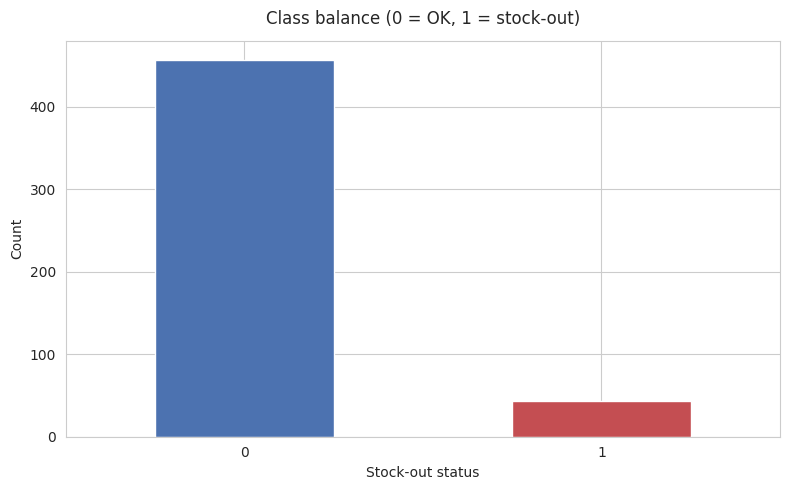

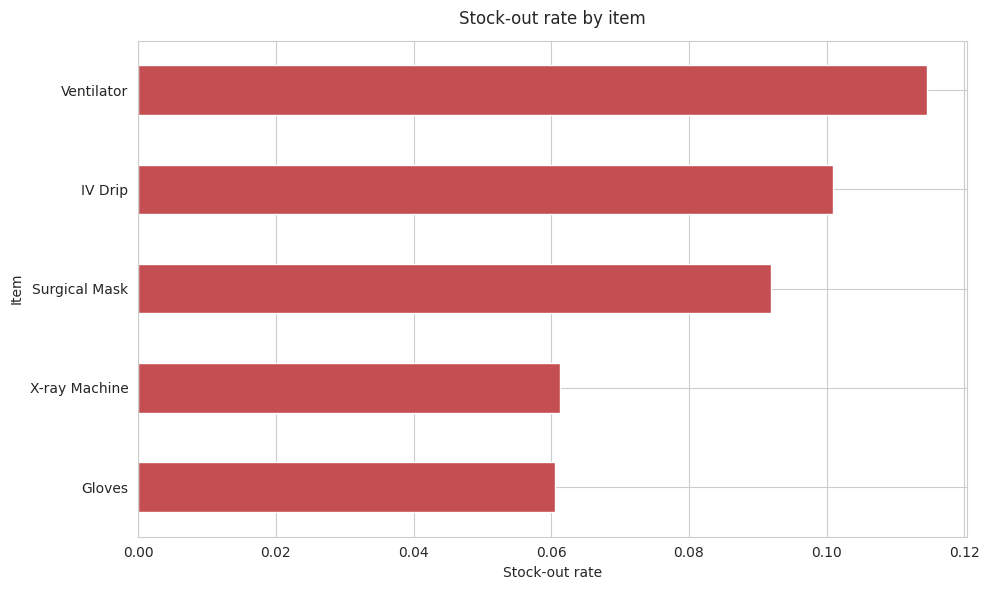

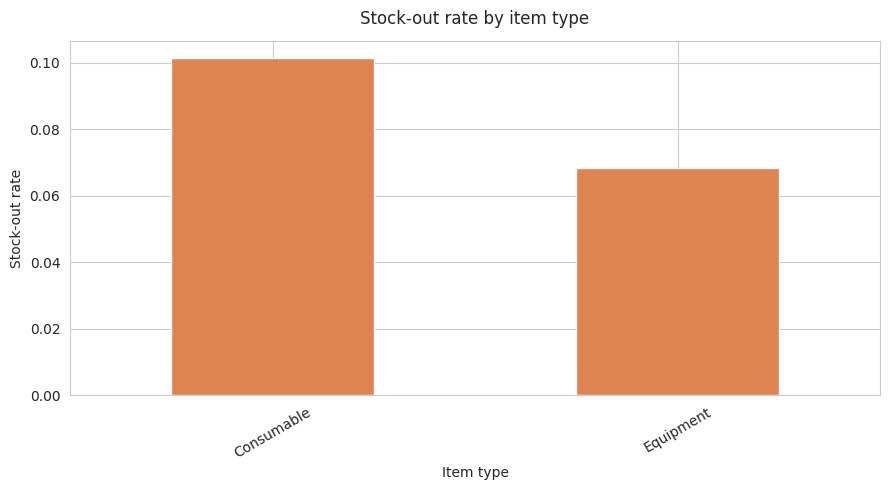

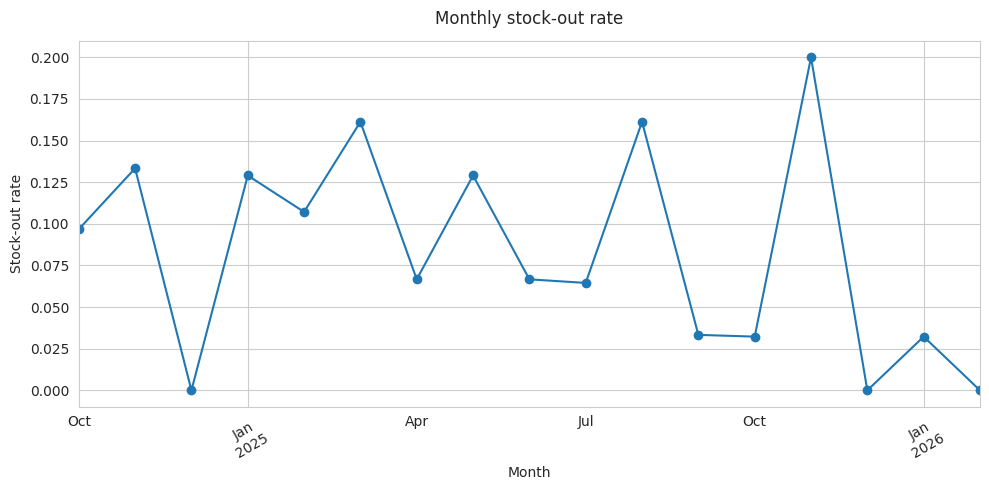

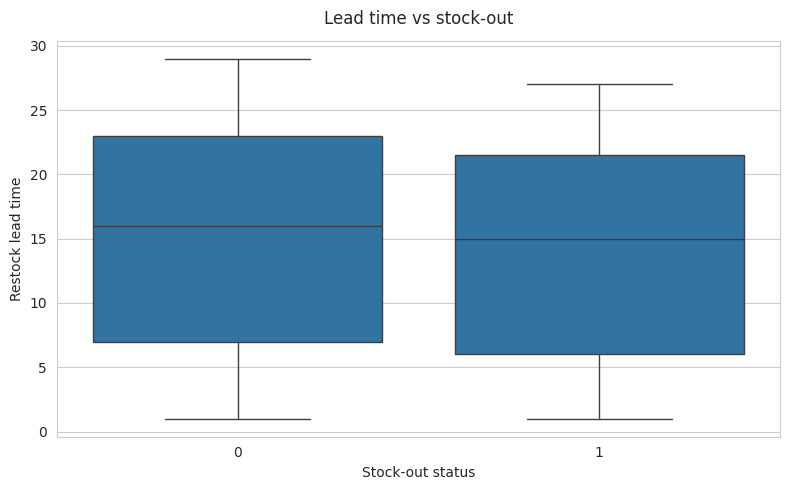

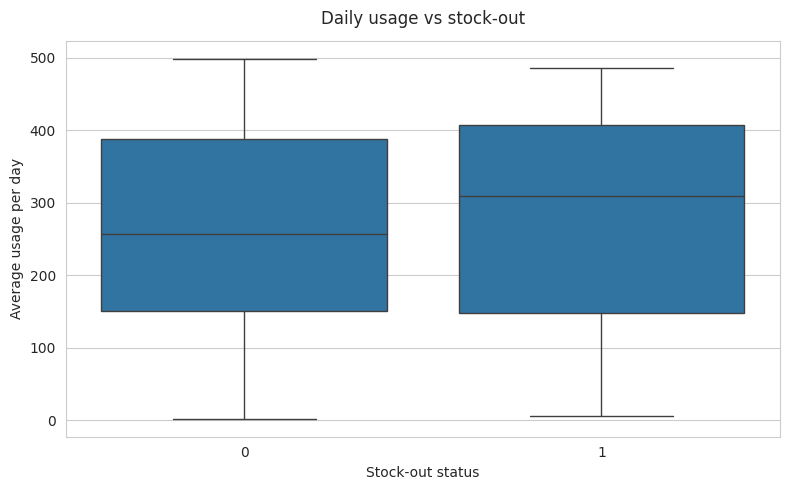

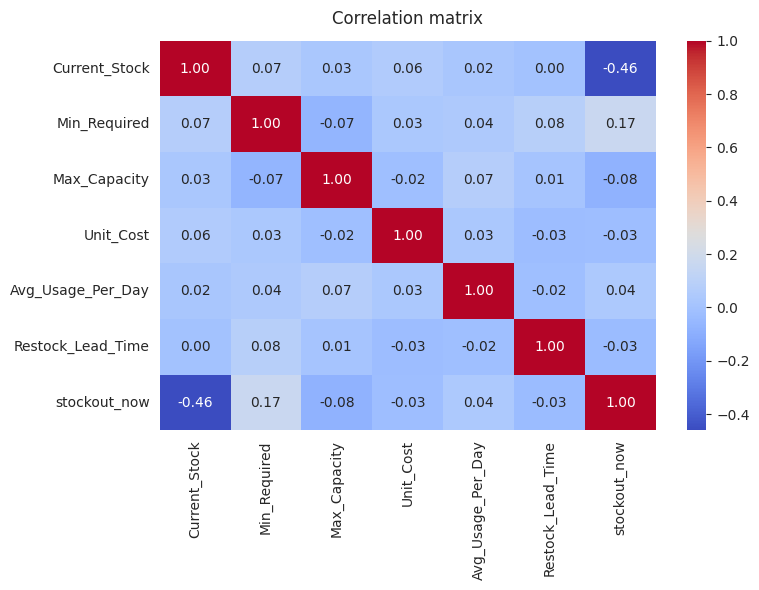

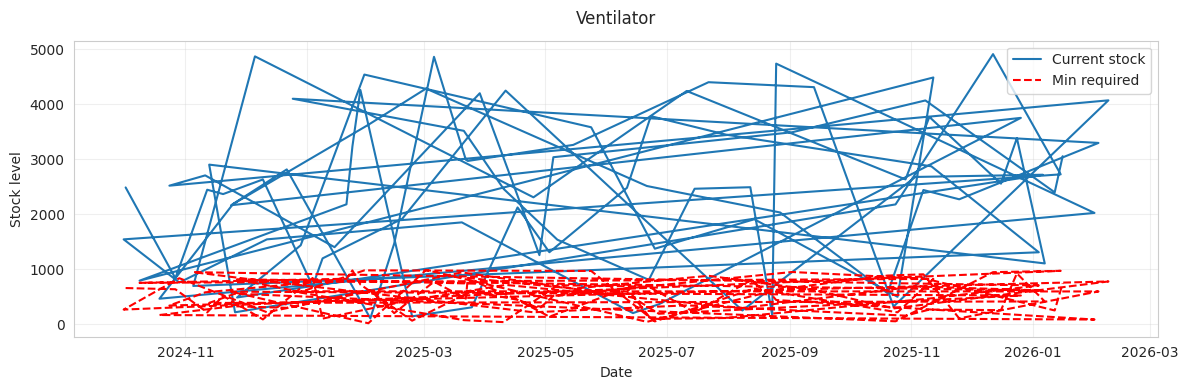

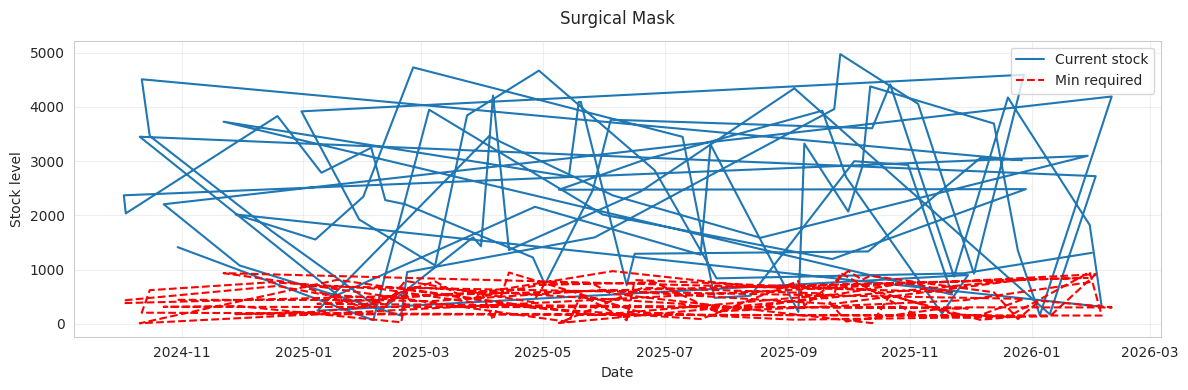

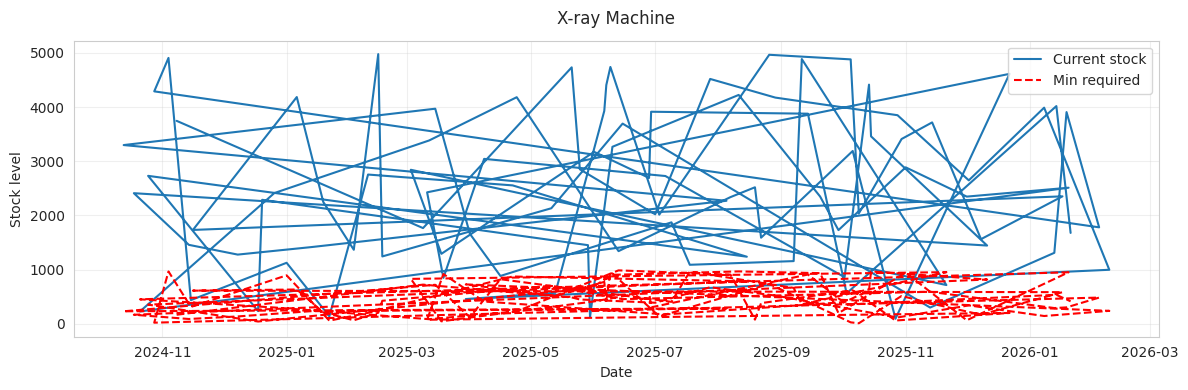

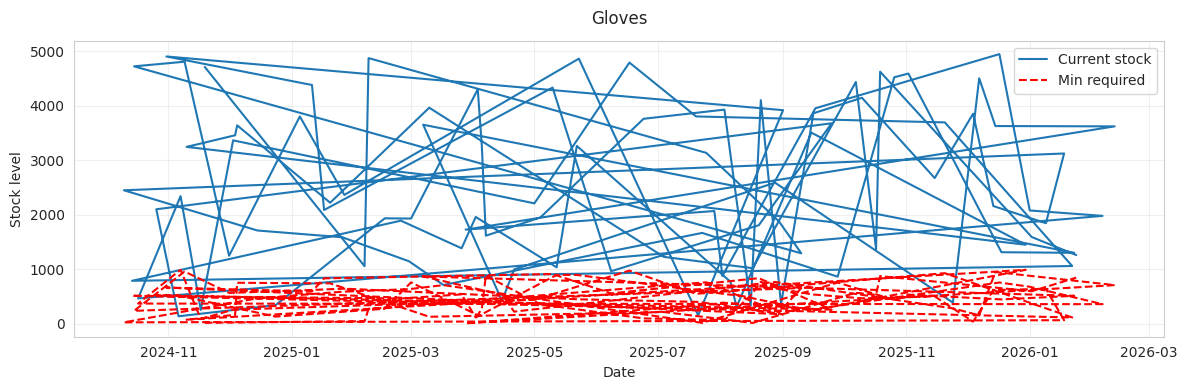

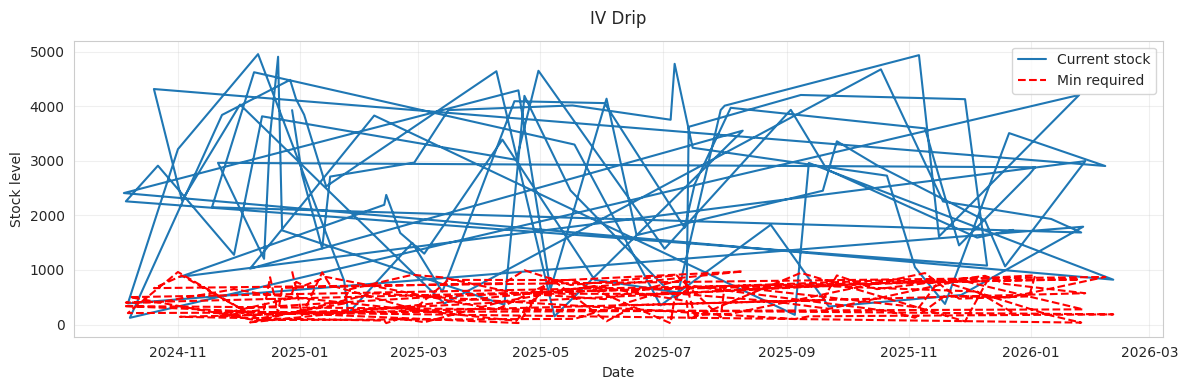

In [ ]:

# Current-state stock-out flag (the definition used in the proposal)
inv["stockout_now"] = (inv["Current_Stock"] < inv["Min_Required"]).astype(int)
print(f"Stock-out rate: {inv['stockout_now'].mean():.1%} ({inv['stockout_now'].sum()} of {len(inv)})")

display(inv[num_cols].describe().T)


# Chart 1: Class balance
plt.figure(figsize=(8, 5))
inv["stockout_now"].value_counts().plot(
    kind="bar", color=["#4C72B0", "#C44E52"]
)
plt.title("Class balance (0 = OK, 1 = stock-out)", pad=12)
plt.xlabel("Stock-out status")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Chart 2: Stock-out rate by item
plt.figure(figsize=(10, 6))
inv.groupby("Item_Name")["stockout_now"].mean().sort_values().plot(
    kind="barh", color="#C44E52"
)
plt.title("Stock-out rate by item", pad=12)
plt.xlabel("Stock-out rate")
plt.ylabel("Item")
plt.tight_layout()
plt.show()


# Chart 3: Stock-out rate by item type
plt.figure(figsize=(9, 5))
inv.groupby("Item_Type")["stockout_now"].mean().plot(
    kind="bar", color="#DD8452"
)
plt.title("Stock-out rate by item type", pad=12)
plt.xlabel("Item type")
plt.ylabel("Stock-out rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 4: Monthly stock-out rate
plt.figure(figsize=(10, 5))
inv.set_index("Date").groupby(pd.Grouper(freq="M"))["stockout_now"].mean().plot(
    marker="o"
)
plt.title("Monthly stock-out rate", pad=12)
plt.xlabel("Month")
plt.ylabel("Stock-out rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 5: Lead time vs stock-out
plt.figure(figsize=(8, 5))
sns.boxplot(data=inv, x="stockout_now", y="Restock_Lead_Time")
plt.title("Lead time vs stock-out", pad=12)
plt.xlabel("Stock-out status")
plt.ylabel("Restock lead time")
plt.tight_layout()
plt.show()


# Chart 6: Daily usage vs stock-out
plt.figure(figsize=(8, 5))
sns.boxplot(data=inv, x="stockout_now", y="Avg_Usage_Per_Day")
plt.title("Daily usage vs stock-out", pad=12)
plt.xlabel("Stock-out status")
plt.ylabel("Average usage per day")
plt.tight_layout()
plt.show()


# Chart 7: Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    inv[num_cols + ["stockout_now"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation matrix", pad=12)
plt.tight_layout()
plt.show()


# Stock trajectory vs minimum threshold, per item
items = inv["Item_Name"].unique()

for it in items:
    plt.figure(figsize=(12, 4))

    s = inv[inv["Item_Name"] == it]

    plt.plot(s["Date"], s["Current_Stock"], label="Current stock")
    plt.plot(s["Date"], s["Min_Required"], "r--", label="Min required")

    plt.title(it, pad=12)
    plt.xlabel("Date")
    plt.ylabel("Stock level")
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


#Merging tables and engineer features

In [ ]:
# Vendor attributes (join on Vendor_ID)
vendor_small = vendor[["Vendor_ID", "Vendor_Avg_Lead_Time", "Cost_Per_Item"]]
df = inv.merge(vendor_small, on="Vendor_ID", how="left")

# Daily financial spend
fin_daily = fin.groupby("Date")["Amount"].agg(daily_spend="sum", daily_txn="count").reset_index()

# Daily patient demand pressure
patient["Bed_Days"] = pd.to_numeric(patient["Bed_Days"], errors="coerce")
pat_daily = patient.groupby("Admission_Date").agg(
    daily_admissions=("Patient_ID", "count"),
    daily_bed_days=("Bed_Days", "sum")).reset_index().rename(columns={"Admission_Date": "Date"})

# Daily staff workload
staff_daily = staff.groupby("Shift_Date").agg(
    daily_staff_hours=("Hours_Worked", "sum"),
    daily_overtime=("Overtime_Hours", "sum"),
    daily_patients_assigned=("Patients_Assigned", "sum")).reset_index().rename(columns={"Shift_Date": "Date"})

for extra in (fin_daily, pat_daily, staff_daily):
    df = df.merge(extra, on="Date", how="left")

ctx_cols = ["daily_spend", "daily_txn", "daily_admissions", "daily_bed_days",
            "daily_staff_hours", "daily_overtime", "daily_patients_assigned"]
df[ctx_cols] = df[ctx_cols].fillna(0)        # no activity recorded that day
df["Cost_Per_Item"] = df["Cost_Per_Item"].fillna(df["Cost_Per_Item"].median())
df["Vendor_Avg_Lead_Time"] = df["Vendor_Avg_Lead_Time"].fillna(df["Vendor_Avg_Lead_Time"].median())

df = df.sort_values(["Item_ID", "Date"]).reset_index(drop=True)
g = df.groupby("Item_ID")

# Features named in the proposal
df["days_of_stock_remaining"] = df["Current_Stock"] / df["Avg_Usage_Per_Day"].replace(0, np.nan)
df["days_of_stock_remaining"] = df["days_of_stock_remaining"].fillna(df["days_of_stock_remaining"].median())
df["stock_buffer_ratio"] = (df["Current_Stock"] - df["Min_Required"]) / df["Min_Required"].replace(0, np.nan)
df["stock_pct_capacity"] = df["Current_Stock"] / df["Max_Capacity"].replace(0, np.nan)
df["lead_time_risk"] = df["Restock_Lead_Time"] - df["days_of_stock_remaining"]
df["patient_demand_pressure"] = df["daily_admissions"] * df["Avg_Usage_Per_Day"]

# Rolling usage (7 and 30 observations per item, past and present only)
df["usage_roll7"]  = g["Avg_Usage_Per_Day"].transform(lambda s: s.rolling(7,  min_periods=1).mean())
df["usage_roll30"] = g["Avg_Usage_Per_Day"].transform(lambda s: s.rolling(30, min_periods=1).mean())
df["stock_change"] = g["Current_Stock"].diff().fillna(0)
df["stock_roll7"]  = g["Current_Stock"].transform(lambda s: s.rolling(7, min_periods=1).mean())

df["month"] = df["Date"].dt.month
df["dayofweek"] = df["Date"].dt.dayofweek

df = df.replace([np.inf, -np.inf], np.nan)
num_feats_all = df.select_dtypes(include=np.number).columns
df[num_feats_all] = df[num_feats_all].fillna(df[num_feats_all].median())

print(df.shape)
display(df.head())

(500, 32)


,Date,Item_ID,Item_Type,Item_Name,Current_Stock,Min_Required,Max_Capacity,Unit_Cost,Avg_Usage_Per_Day,Restock_Lead_Time,...,stock_buffer_ratio,stock_pct_capacity,lead_time_risk,patient_demand_pressure,usage_roll7,usage_roll30,stock_change,stock_roll7,month,dayofweek
0,2024-10-02,100,Equipment,Ventilator,2487,656,3556,5832.29,55,12,...,2.791159,0.699381,-33.218182,0.0,55.0,55.0,0.0,2487.0,10,2
1,2024-10-27,100,Equipment,Ventilator,835,634,2523,3695.18,426,7,...,0.317035,0.330955,5.039906,0.0,240.5,240.5,-1652.0,1661.0,10,6
2,2024-10-30,100,Equipment,Surgical Mask,1415,444,1004,4817.11,110,9,...,2.186937,1.409363,-3.863636,0.0,197.0,197.0,580.0,1579.0,10,2
3,2024-11-08,100,Equipment,X-ray Machine,3745,167,5193,7093.88,51,26,...,21.425150,0.721163,-47.431373,0.0,160.5,160.5,2330.0,2120.5,11,4
4,2024-11-12,100,Consumable,Ventilator,2445,213,2961,2860.00,72,6,...,10.478873,0.825735,-27.958333,0.0,142.8,142.8,-1300.0,2185.4,11,1


#Build forecasting target and chronological split

In [ ]:
HORIZON = 7   # predict a stock-out within the next 7 observations of the same item

g = df.groupby("Item_ID")["stockout_now"]
future = pd.concat([g.shift(-k) for k in range(1, HORIZON + 1)], axis=1)
df["target"] = future.max(axis=1)
df = df[future.notna().any(axis=1)].copy()     # drop final rows with no future
df["target"] = df["target"].astype(int)

print(f"Target positive rate: {df['target'].mean():.1%}")

cat_features = ["Item_Type", "Item_Name", "Vendor_ID"]
drop_cols = ["target", "Date", "Item_ID"]
feature_cols = [c for c in df.columns if c not in drop_cols]

# Chronological 80/20 split
df = df.sort_values("Date").reset_index(drop=True)
split = int(len(df) * 0.8)
train_df, test_df = df.iloc[:split], df.iloc[split:]

# Last 15% of train is a validation block (early stopping and threshold choice)
vsplit = int(len(train_df) * 0.85)
fit_df, val_df = train_df.iloc[:vsplit], train_df.iloc[vsplit:]

X_tr, y_tr = train_df[feature_cols], train_df["target"]
X_fit, y_fit = fit_df[feature_cols], fit_df["target"]
X_val, y_val = val_df[feature_cols], val_df["target"]
X_te, y_te = test_df[feature_cols], test_df["target"]

print(f"fit {len(fit_df)} | val {len(val_df)} | test {len(test_df)}")
print("Positives:", y_fit.sum(), y_val.sum(), y_te.sum())

Target positive rate: 46.3%
fit 333 | val 59 | test 98
Positives: 181 27 19


#Baselines (naive and Random forest and XGBoost)

In [ ]:
def report(name, y_true, prob, thr=0.5):
    pred = (np.asarray(prob) >= thr).astype(int)
    return {"Model": name,
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_true, prob) if y_true.nunique() > 1 else np.nan,
            "PR_AUC": average_precision_score(y_true, prob)}

results = []

#Always-zero baseline
results.append(report("Always no stock-out", y_te, np.zeros(len(y_te))))
pd.DataFrame(results).round(3)

# "A stock-out in the future only if stock is below minimum right now"
results.append(report("Naive (persistence)", y_te, test_df["stockout_now"].values.astype(float)))
pd.DataFrame(results).round(3)

#Random dorest (class balanced)
rf_cols = [c for c in feature_cols if c not in cat_features]

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                            min_samples_leaf=3, random_state=SEED, n_jobs=-1)
rf.fit(X_tr[rf_cols], y_tr)
results.append(report("Random Forest (balanced)", y_te, rf.predict_proba(X_te[rf_cols])[:, 1]))
pd.DataFrame(results).round(3)

#XGBoost Weighted
from xgboost import XGBClassifier

spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)   # cost-sensitive weight
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=spw, eval_metric="aucpr",
                    random_state=SEED, verbosity=0)
xgb.fit(X_tr[rf_cols], y_tr)
results.append(report("XGBoost (weighted)", y_te, xgb.predict_proba(X_te[rf_cols])[:, 1]))
pd.DataFrame(results).round(3)

#Comparison table
baseline_df = pd.DataFrame(results).round(3)
display(baseline_df)

,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Always no stock-out,0.000,0.000,0.000,0.500,0.194
1,Naive (persistence),0.143,0.053,0.077,0.488,0.191
2,Random Forest (balanced),0.210,0.895,0.340,0.694,0.492
3,XGBoost (weighted),0.208,0.842,0.333,0.633,0.420


#Train CatBoost and choose cost-based threshold

Negatives 184, positives 208, imbalance ratio 0.9
Grid search: 24/24 done
Top cross-validation settings:


,weight,depth,lr,l2,cv_pr_auc,folds_used
7,none,6,0.08,10,0.612,5
2,none,4,0.08,3,0.610,5
16,full,4,0.03,3,0.608,5
18,full,4,0.08,3,0.608,5
0,none,4,0.03,3,0.607,5
13,sqrt,6,0.03,10,0.603,5
1,none,4,0.03,10,0.598,5
20,full,6,0.03,3,0.598,5


Best settings: {'weight': 'none', 'depth': 6, 'lr': 0.08, 'l2': 10, 'cv_pr_auc': 0.6121021855145848, 'folds_used': 5}
Trees used: 55


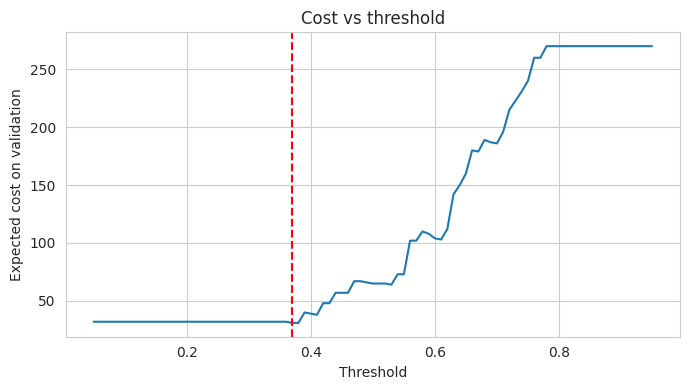

Cost-optimal threshold: 0.37

Model comparison (test set):


,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Always no stock-out,0.000,0.000,0.000,0.500,0.194
1,Naive (persistence),0.143,0.053,0.077,0.488,0.191
2,Random Forest (balanced),0.210,0.895,0.340,0.694,0.492
3,XGBoost (weighted),0.208,0.842,0.333,0.633,0.420
4,CatBoost (thr 0.50),0.207,0.895,0.337,0.738,0.550
5,CatBoost (cost thr 0.37),0.200,1.000,0.333,0.738,0.550


              precision    recall  f1-score   support

No stock-out       1.00      0.04      0.07        79
   Stock-out       0.20      1.00      0.33        19

    accuracy                           0.22        98
   macro avg       0.60      0.52      0.20        98
weighted avg       0.84      0.22      0.12        98

TN=3  FP=76  FN=0  TP=19
Expected cost on test: 76


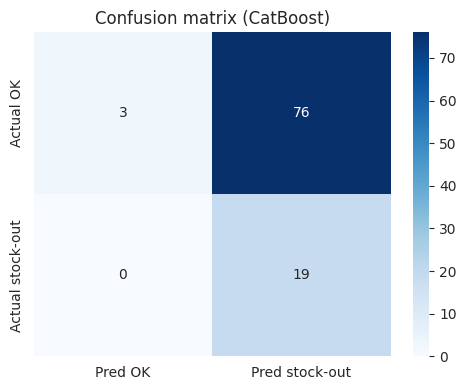

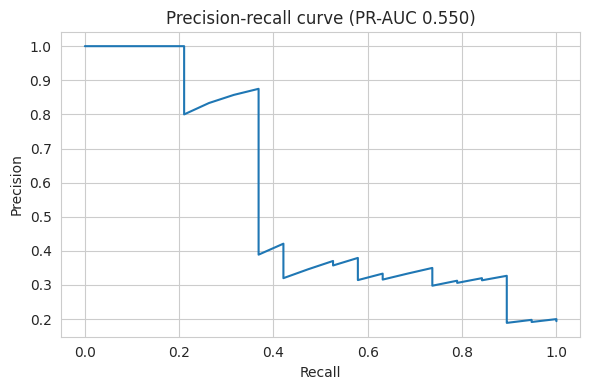

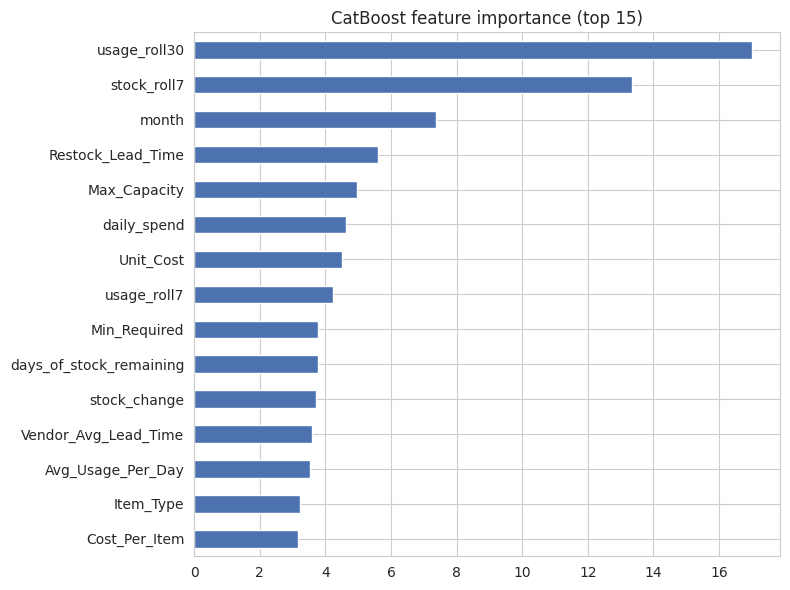

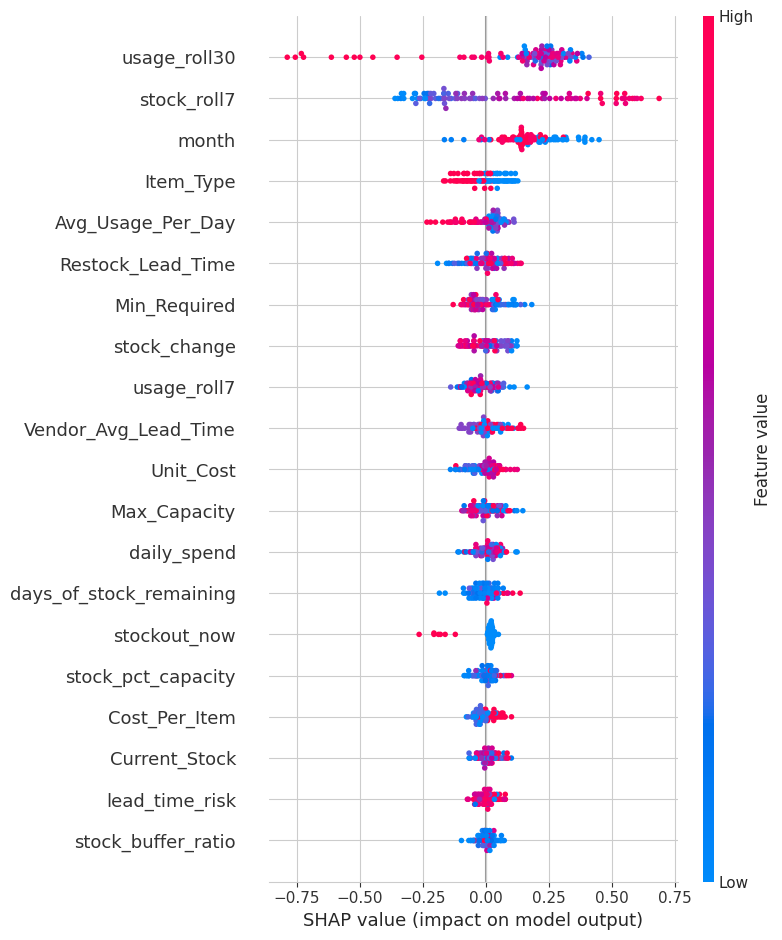

SHAP array shape: (98, 30)
Model classes: [0 1]
Example predicted stock-out probability: 0.7043503301677507
Example raw model prediction: [0.86810065]

Performance per item:


,Item,n,actual_positives,recall,precision
0,Gloves,19,2,1.0,0.111
1,IV Drip,21,5,1.0,0.238
2,Surgical Mask,20,4,1.0,0.211
3,Ventilator,20,3,1.0,0.150
4,X-ray Machine,18,5,1.0,0.294


In [ ]:
import shap
from catboost import Pool

# ---------- 0. Prerequisite check ----------
needed = ["X_tr", "y_tr", "X_fit", "y_fit", "X_val", "y_val", "X_te", "y_te",
          "test_df", "feature_cols", "cat_features", "SEED", "report", "results"]
missing = [v for v in needed if v not in globals()]
if missing:
    raise RuntimeError(f"Run the earlier steps first. Missing: {missing}")

# ---------- 1. Class weight options ----------
neg, pos = (y_tr == 0).sum(), (y_tr == 1).sum()
full_ratio = neg / max(pos, 1)
weight_options = {"none": 1.0, "sqrt": float(np.sqrt(full_ratio)), "full": float(full_ratio)}
print(f"Negatives {neg}, positives {pos}, imbalance ratio {full_ratio:.1f}")

# ---------- 2. Time-series CV grid (takes a few minutes) ----------
grid = [(w, d, lr, l2) for w in weight_options for d in (4, 6)
        for lr in (0.03, 0.08) for l2 in (3, 10)]
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []

for i, (w_name, depth, lr, l2) in enumerate(grid, 1):
    scores = []
    for tr_idx, va_idx in tscv.split(X_tr):
        ytr_f, yva_f = y_tr.iloc[tr_idx], y_tr.iloc[va_idx]
        if ytr_f.sum() == 0 or yva_f.sum() == 0:
            continue
        m = CatBoostClassifier(iterations=300, depth=depth, learning_rate=lr,
                               l2_leaf_reg=l2, class_weights=[1, weight_options[w_name]],
                               random_seed=SEED, verbose=0, thread_count=-1)
        m.fit(X_tr.iloc[tr_idx], ytr_f, cat_features=cat_features)
        scores.append(average_precision_score(yva_f, m.predict_proba(X_tr.iloc[va_idx])[:, 1]))
    cv_rows.append({"weight": w_name, "depth": depth, "lr": lr, "l2": l2,
                    "cv_pr_auc": np.mean(scores) if scores else np.nan,
                    "folds_used": len(scores)})
    print(f"Grid search: {i}/{len(grid)} done", end="\r")

cv_df = pd.DataFrame(cv_rows).sort_values("cv_pr_auc", ascending=False)
print("\nTop cross-validation settings:")
display(cv_df.head(8).round(3))

if cv_df["cv_pr_auc"].notna().any():
    best = cv_df.dropna(subset=["cv_pr_auc"]).iloc[0].to_dict()
else:
    print("No fold had positives. Using fallback settings.")
    best = {"depth": 4, "lr": 0.05, "l2": 5, "weight": "sqrt"}
print("Best settings:", best)

# ---------- 3. Final parameters and costs ----------
FN_COST, FP_COST = 10, 1     # a missed stock-out costs 10x a false alarm (justify in write-up)

final_params = dict(depth=int(best["depth"]), learning_rate=float(best["lr"]),
                    l2_leaf_reg=float(best["l2"]),
                    class_weights=[1, weight_options[best["weight"]]],
                    random_seed=SEED, verbose=0, thread_count=-1)

# ---------- 4. Early stopping to find tree count ----------
if y_val.sum() > 0:
    stage1 = CatBoostClassifier(iterations=1500, early_stopping_rounds=50,
                                eval_metric="PRAUC", **final_params)
    stage1.fit(X_fit, y_fit, cat_features=cat_features,
               eval_set=(X_val, y_val), use_best_model=True)
    best_iters = max(stage1.get_best_iteration() + 1, 50)
    val_prob = stage1.predict_proba(X_val)[:, 1]
else:
    print("Validation block has no positives. Using 300 trees and threshold 0.50.")
    best_iters, val_prob = 300, None
print("Trees used:", best_iters)

# ---------- 5. Cost-optimal threshold ----------
thresholds = np.linspace(0.05, 0.95, 91)
if val_prob is not None:
    costs = []
    for t in thresholds:
        tn, fp, fn, tp = confusion_matrix(y_val, (val_prob >= t).astype(int), labels=[0, 1]).ravel()
        costs.append(FN_COST * fn + FP_COST * fp)
    best_thr = float(thresholds[int(np.argmin(costs))])
    plt.figure(figsize=(7, 4))
    plt.plot(thresholds, costs); plt.axvline(best_thr, color="r", linestyle="--")
    plt.xlabel("Threshold"); plt.ylabel("Expected cost on validation")
    plt.title("Cost vs threshold"); plt.tight_layout(); plt.show()
else:
    best_thr = 0.5
print(f"Cost-optimal threshold: {best_thr:.2f}")

# ---------- 6. Refit on full training period, predict test set ----------
final_model = CatBoostClassifier(iterations=best_iters, **final_params)
final_model.fit(X_tr, y_tr, cat_features=cat_features)
test_prob = final_model.predict_proba(X_te)[:, 1]

# ---------- 7. Evaluation ----------
results = [r for r in results if not r["Model"].startswith("CatBoost")]   # safe to rerun
results.append(report("CatBoost (thr 0.50)", y_te, test_prob, thr=0.5))
results.append(report(f"CatBoost (cost thr {best_thr:.2f})", y_te, test_prob, thr=best_thr))
print("\nModel comparison (test set):")
display(pd.DataFrame(results).round(3))

pred = (test_prob >= best_thr).astype(int)
print(classification_report(y_te, pred, target_names=["No stock-out", "Stock-out"], zero_division=0))

cm = confusion_matrix(y_te, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Expected cost on test: {FN_COST * fn + FP_COST * fp}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred OK", "Pred stock-out"],
            yticklabels=["Actual OK", "Actual stock-out"])
plt.title("Confusion matrix (CatBoost)")
plt.tight_layout(); plt.show()

p, r, _ = precision_recall_curve(y_te, test_prob)
plt.figure(figsize=(6, 4))
plt.plot(r, p)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-recall curve (PR-AUC {average_precision_score(y_te, test_prob):.3f})")
plt.tight_layout(); plt.show()

# ---------- 8. Interpretability ----------
imp = pd.Series(final_model.get_feature_importance(), index=feature_cols).sort_values()
plt.figure(figsize=(8, 6))
imp.tail(15).plot(kind="barh", color="#4C72B0")
plt.title("CatBoost feature importance (top 15)")
plt.tight_layout(); plt.show()

shap_all = final_model.get_feature_importance(Pool(X_te, y_te, cat_features=cat_features),
                                              type="ShapValues")
shap_vals = shap_all[:, :-1]
X_plot = X_te.copy()
for c in cat_features:
    X_plot[c] = X_plot[c].astype("category").cat.codes
shap.summary_plot(shap_vals, X_plot, show=True)

print("SHAP array shape:", shap_vals.shape)
print("Model classes:", final_model.classes_)
print("Example predicted stock-out probability:",
      final_model.predict_proba(X_te.iloc[[0]])[0, 1])
print("Example raw model prediction:",
      final_model.predict(X_te.iloc[[0]], prediction_type="RawFormulaVal"))

# ---------- 9. Performance per item ----------
test_eval = test_df[["Item_Name", "target"]].copy()
test_eval["pred"] = pred
rows = []
for item, d in test_eval.groupby("Item_Name"):
    rows.append({"Item": item, "n": len(d), "actual_positives": int(d["target"].sum()),
                 "recall": recall_score(d["target"], d["pred"], zero_division=0),
                 "precision": precision_score(d["target"], d["pred"], zero_division=0)})
print("\nPerformance per item:")
display(pd.DataFrame(rows).round(3))

#Supplementary analyses

In [ ]:

# CELL 1.2 — ABLATION WITHOUT stockout_now

from sklearn.metrics import average_precision_score, roc_auc_score
from catboost import CatBoostClassifier
import pandas as pd

# 1. Check prerequisites
needed = [
    "X_tr", "y_tr", "X_te", "y_te",
    "cat_features", "final_params", "best_iters",
    "test_prob"
]
missing = [v for v in needed if v not in globals()]
if missing:
    raise RuntimeError(f"Run the main CatBoost cell first. Missing: {missing}")

# 2. Remove the current-state flag from training and test features
if "stockout_now" not in X_tr.columns:
    raise ValueError(
        "'stockout_now' is not a column in X_tr. "
        "Check how feature_cols was constructed."
    )

X_tr_ablation = X_tr.drop(columns=["stockout_now"]).copy()
X_te_ablation = X_te.drop(columns=["stockout_now"]).copy()

# Keep only categorical features that remain
cat_features_ablation = [
    c for c in cat_features
    if isinstance(c, str) and c != "stockout_now"
]

# 3. Train CatBoost using the same selected hyperparameters
ablation_model = CatBoostClassifier(
    iterations=best_iters,
    **final_params
)

ablation_model.fit(
    X_tr_ablation,
    y_tr,
    cat_features=cat_features_ablation
)

# 4. Predict on the SAME untouched test set
ablation_prob = ablation_model.predict_proba(
    X_te_ablation
)[:, 1]

# 5. Calculate threshold-independent metrics
original_pr_auc = average_precision_score(y_te, test_prob)
original_roc_auc = roc_auc_score(y_te, test_prob)

ablation_pr_auc = average_precision_score(y_te, ablation_prob)
ablation_roc_auc = roc_auc_score(y_te, ablation_prob)

ablation_results = pd.DataFrame([
    {
        "Model": "CatBoost with stockout_now",
        "PR-AUC": original_pr_auc,
        "ROC-AUC": original_roc_auc
    },
    {
        "Model": "CatBoost without stockout_now",
        "PR-AUC": ablation_pr_auc,
        "ROC-AUC": ablation_roc_auc
    }
])

print("ABLATION RESULTS")
display(ablation_results.round(4))

print("\nDifference (without flag minus with flag):")
print(f"PR-AUC difference:  {ablation_pr_auc - original_pr_auc:+.4f}")
print(f"ROC-AUC difference: {ablation_roc_auc - original_roc_auc:+.4f}")

print(
    "\nInterpretation: Compare the metric differences. "
    "Small decreases suggest performance is largely maintained; "
    "larger decreases suggest the flag contributes more predictive information."
)


ABLATION RESULTS


,Model,PR-AUC,ROC-AUC
0,CatBoost with stockout_now,0.5503,0.7382
1,CatBoost without stockout_now,0.3544,0.6556



Difference (without flag minus with flag):
PR-AUC difference:  -0.1959
ROC-AUC difference: -0.0826

Interpretation: Compare the metric differences. Small decreases suggest performance is largely maintained; larger decreases suggest the flag contributes more predictive information.


In [ ]:
%pip install imbalanced-learn

In [ ]:

# CELL 3.1 — COST-SENSITIVE CATBOOST VS SMOTENC

from imblearn.over_sampling import SMOTENC
from catboost import CatBoostClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# 1. Check prerequisites
needed = [
    "X_tr", "y_tr", "X_te", "y_te",
    "cat_features", "final_params", "best_iters",
    "test_prob", "best_thr", "SEED"
]
missing = [v for v in needed if v not in globals()]
if missing:
    raise RuntimeError(f"Run the main CatBoost cell first. Missing: {missing}")

# 2. Identify categorical column names
cat_cols = [
    c for c in cat_features
    if isinstance(c, str) and c in X_tr.columns
]

if not cat_cols:
    raise ValueError(
        "No categorical column names were found. "
        "Check the cat_features variable."
    )

# 3. Prepare training data for SMOTENC
X_smote_input = X_tr.copy()
X_smote_test = X_te.copy()

# SMOTENC handles mixed numeric and categorical data.
# Convert categorical values consistently to strings.
for c in cat_cols:
    X_smote_input[c] = X_smote_input[c].fillna(
        "__MISSING__"
    ).astype(str)
    X_smote_test[c] = X_smote_test[c].fillna(
        "__MISSING__"
    ).astype(str)

y_smote_input = pd.Series(
    np.asarray(y_tr),
    name=getattr(y_tr, "name", None)
).reset_index(drop=True)

X_smote_input = X_smote_input.reset_index(drop=True)

# 4. Check minority-class size before oversampling
class_counts = y_smote_input.value_counts()
print("Original training class counts:")
display(class_counts.rename("count").to_frame())

minority_count = int(class_counts.min())

if minority_count < 2:
    raise ValueError(
        "SMOTENC requires at least two observations in the minority class."
    )

k = min(5, minority_count - 1)

# 5. Oversample training data ONLY
smote = SMOTENC(
    categorical_features=cat_cols,
    random_state=SEED,
    k_neighbors=k,
    sampling_strategy="auto"
)

X_resampled, y_resampled = smote.fit_resample(
    X_smote_input,
    y_smote_input
)

print("\nClass counts after SMOTENC:")
display(pd.Series(y_resampled).value_counts().rename("count").to_frame())

print(f"Training observations before SMOTENC: {len(X_tr)}")
print(f"Training observations after SMOTENC:  {len(X_resampled)}")
print(f"Test observations (unchanged):        {len(X_te)}")

# 6. Train CatBoost on the oversampled training data.
# Do not also apply the original class weights:
# oversampling is the imbalance-handling method for this model.
smote_params = final_params.copy()
smote_params["class_weights"] = [1, 1]

smote_model = CatBoostClassifier(
    iterations=best_iters,
    **smote_params
)

smote_model.fit(
    X_resampled,
    y_resampled,
    cat_features=cat_cols
)

# 7. Predict on the same untouched test set
smote_prob = smote_model.predict_proba(
    X_smote_test
)[:, 1]

# 8. Compare threshold-independent metrics
# test_prob is from your existing cost-sensitive CatBoost model.
cost_pr_auc = average_precision_score(y_te, test_prob)
cost_roc_auc = roc_auc_score(y_te, test_prob)

smote_pr_auc = average_precision_score(y_te, smote_prob)
smote_roc_auc = roc_auc_score(y_te, smote_prob)

# Use the same preselected threshold for a direct,
# like-for-like classification comparison.
cost_pred = (test_prob >= best_thr).astype(int)
smote_pred = (smote_prob >= best_thr).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Cost-sensitive CatBoost",
        "PR-AUC": cost_pr_auc,
        "ROC-AUC": cost_roc_auc,
        "Threshold": best_thr,
        "Precision": precision_score(
            y_te, cost_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_te, cost_pred, zero_division=0
        ),
        "F1": f1_score(
            y_te, cost_pred, zero_division=0
        )
    },
    {
        "Model": "CatBoost + SMOTENC",
        "PR-AUC": smote_pr_auc,
        "ROC-AUC": smote_roc_auc,
        "Threshold": best_thr,
        "Precision": precision_score(
            y_te, smote_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_te, smote_pred, zero_division=0
        ),
        "F1": f1_score(
            y_te, smote_pred, zero_division=0
        )
    }
])

print("\nCOST-SENSITIVE VS SMOTENC — TEST RESULTS")
display(comparison.round(4))

print("\nMetric differences (SMOTENC minus cost-sensitive):")
for metric in ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]:
    diff = (
        comparison.loc[1, metric]
        - comparison.loc[0, metric]
    )
    print(f"{metric}: {diff:+.4f}")

# 9. Confusion matrices on the same test observations
print("\nCost-sensitive CatBoost confusion matrix:")
print(confusion_matrix(y_te, cost_pred, labels=[0, 1]))

print("\nCatBoost + SMOTENC confusion matrix:")
print(confusion_matrix(y_te, smote_pred, labels=[0, 1]))

if smote_pr_auc > cost_pr_auc:
    print("\nHigher PR-AUC: CatBoost + SMOTENC.")
elif smote_pr_auc < cost_pr_auc:
    print("\nHigher PR-AUC: Cost-sensitive CatBoost.")
else:
    print("\nPR-AUC is tied.")

if smote_roc_auc > cost_roc_auc:
    print("Higher ROC-AUC: CatBoost + SMOTENC.")
elif smote_roc_auc < cost_roc_auc:
    print("Higher ROC-AUC: Cost-sensitive CatBoost.")
else:
    print("ROC-AUC is tied.")


Original training class counts:


,count
target,
1,208
0,184



Class counts after SMOTENC:


,count
target,
1,208
0,208


Training observations before SMOTENC: 392
Training observations after SMOTENC:  416
Test observations (unchanged):        98

COST-SENSITIVE VS SMOTENC — TEST RESULTS


,Model,PR-AUC,ROC-AUC,Threshold,Precision,Recall,F1
0,Cost-sensitive CatBoost,0.5503,0.7382,0.37,0.2000,1.0000,0.3333
1,CatBoost + SMOTENC,0.4042,0.6975,0.37,0.1758,0.8421,0.2909



Metric differences (SMOTENC minus cost-sensitive):
PR-AUC: -0.1461
ROC-AUC: -0.0406
Precision: -0.0242
Recall: -0.1579
F1: -0.0424

Cost-sensitive CatBoost confusion matrix:
[[ 3 76]
 [ 0 19]]

CatBoost + SMOTENC confusion matrix:
[[ 4 75]
 [ 3 16]]

Higher PR-AUC: Cost-sensitive CatBoost.
Higher ROC-AUC: Cost-sensitive CatBoost.


#evaluate with an alert budget and honest baselines

In [ ]:
FN_COST, FP_COST = 10, 1   # only needed if not already defined

def cost_threshold(y_true, prob, fn_cost, fp_cost):
    thresholds = np.linspace(0.05, 0.95, 91)
    costs = []
    for t in thresholds:
        tn, fp, fn, tp = confusion_matrix(y_true, (np.asarray(prob) >= t).astype(int), labels=[0, 1]).ravel()
        costs.append(fn_cost * fn + fp_cost * fp)
    return float(thresholds[int(np.argmin(costs))])

def add_result(name, y_true, prob, thr):
    global results
    results = [r for r in results if r["Model"] != name]    # safe to rerun
    results.append(report(name, y_true, prob, thr=thr))

In [ ]:
y_arr = y_te.values
n, n_pos = len(y_arr), int(y_arr.sum())
order = np.argsort(-test_prob)

# 1. Alert-budget table
rows = []
for frac in (0.05, 0.10, 0.20, 0.30, 0.50):
    k = int(round(frac * n))
    flag = np.zeros(n, dtype=int); flag[order[:k]] = 1
    tp = int(((flag == 1) & (y_arr == 1)).sum()); fp = k - tp; fn = n_pos - tp
    rows.append({"alert budget": f"top {int(frac*100)}%", "alerts": k,
                 "precision": tp / k, "recall": tp / n_pos,
                 "lift vs base rate": (tp / k) / (n_pos / n),
                 "TP": tp, "FP": fp, "FN": fn})
display(pd.DataFrame(rows).round(3))

# 2. Cost comparison across cost ratios
rows = []
for fn_c in (2, 3, 5, 10):
    thr = cost_threshold(y_val, val_prob, fn_c, 1) if val_prob is not None else 0.5
    p = (test_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, p, labels=[0, 1]).ravel()
    rows.append({"FN:FP": f"{fn_c}:1", "break-even precision": round(1 / (fn_c + 1), 3),
                 "threshold": round(thr, 2), "alerts": int(p.sum()),
                 "model cost": fn_c * fn + fp,
                 "alert-all cost": (n - n_pos),
                 "never-alert cost": fn_c * n_pos})
display(pd.DataFrame(rows))

# 3. Bootstrap on ranking metrics (CatBoost vs persistence and vs random)
rng = np.random.default_rng(SEED)
nv = test_df["stockout_now"].values.astype(float)
d_roc, d_pr, lift = [], [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    yb = y_arr[idx]
    if yb.sum() == 0 or yb.sum() == n:
        continue
    d_roc.append(roc_auc_score(yb, test_prob[idx]) - roc_auc_score(yb, nv[idx]))
    d_pr.append(average_precision_score(yb, test_prob[idx]) - average_precision_score(yb, nv[idx]))
    lift.append(average_precision_score(yb, test_prob[idx]) - yb.mean())

for name, v in [("ROC-AUC gain over persistence", d_roc),
                ("PR-AUC gain over persistence", d_pr),
                ("PR-AUC gain over base rate", lift)]:
    print(f"{name}: mean {np.mean(v):.3f}, 95% CI [{np.quantile(v, .025):.3f}, {np.quantile(v, .975):.3f}]")

,alert budget,alerts,precision,recall,lift vs base rate,TP,FP,FN
0,top 5%,5,0.800,0.211,4.126,4,1,15
1,top 10%,10,0.700,0.368,3.611,7,3,12
2,top 20%,20,0.400,0.421,2.063,8,12,11
3,top 30%,29,0.379,0.579,1.956,11,18,8
4,top 50%,49,0.306,0.789,1.579,15,34,4


,FN:FP,break-even precision,threshold,alerts,model cost,alert-all cost,never-alert cost
0,2:1,0.333,0.41,94,78,79,38
1,3:1,0.250,0.37,95,76,79,57
2,5:1,0.167,0.37,95,76,79,95
3,10:1,0.091,0.37,95,76,79,190


ROC-AUC gain over persistence: mean 0.250, 95% CI [0.085, 0.399]
PR-AUC gain over persistence: mean 0.359, 95% CI [0.162, 0.555]
PR-AUC gain over base rate: mean 0.363, 95% CI [0.167, 0.555]
